# Milestone 3: adding person-job fit features to the logistic regression
**Data:** NSCG 2023 respondents linked to O*NET work values (`nscg2023_onet30_2_subset_1.csv`, 74,016 rows).

**Questions**
- **Track A:** how much do fit-related features improve prediction over the background-only baseline?
- **Track B:** which ways of scoring fit actually help?

**Design:** the same background baseline as October, plus (1) the person's work values, (2) the occupation's O*NET work values, and (3) fit scores that compare the two. Fit scores are tested both on their own and *on top of* both main effects, because a gap like `person - job` contains the person's own values and would otherwise get credit for them. Every model is a class-balanced logistic regression evaluated with the same occupation-grouped folds, and differences are tested with a paired bootstrap over occupations.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, confusion_matrix)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
DATA_PATH = "nscg2023_onet30_2_subset_1.csv"   # change if the file lives elsewhere

## 1. Load data, define target and groups
- **Target:** `JOBSATIS` 1 or 2 = satisfied (1), 3 or 4 = unsatisfied (0). Verify the coding against the NSCG codebook.
- **Groups:** `SOC2018_CODE` is missing for about 70% of rows (group-mean mappings), so it can't define folds. `ONET_PROFILE_ID` is complete and maps one-to-one to the NSCG occupation code (123 occupations), and it determines the O*NET values a person receives. Grouping by it means no occupation's O*NET profile appears in both train and test.

In [2]:
df = pd.read_csv(DATA_PATH, low_memory=False)
y = df["JOBSATIS"].isin([1, 2]).astype(int).values
groups = df["ONET_PROFILE_ID"].values

print("rows:", len(df), "| occupations (groups):", len(np.unique(groups)))
print(f"satisfied {y.mean():.1%} | unsatisfied {1 - y.mean():.1%} ({int((1 - y).sum())} people)")
print("missing SOC2018_CODE:", f"{df.SOC2018_CODE.isna().mean():.0%}", "| missing in model columns:",
      int(df[["AGE","SEX_2023","DGRDG","OCEDRLP","SUPWK","WAPRI"]].isna().sum().sum()))
print("rows per occupation (min/median/max):", df.groupby(groups).size().agg(["min","median","max"]).tolist())
print("mapping flagged as proxy:", f"{df.MAPPING_IS_PROXY.mean():.0%}")

rows: 74016 | occupations (groups): 123
satisfied 90.1% | unsatisfied 9.9% (7361 people)
missing SOC2018_CODE: 70% | missing in model columns: 0
rows per occupation (min/median/max): [12.0, 369.0, 4048.0]
mapping flagged as proxy: 31%


## 2. Features
**Baseline (unchanged from October):** `AGE`, `SEX_2023`, `DGRDG`, `OCEDRLP`, `SUPWK`, `WAPRI`.

**Person values:** the nine `FAC*` items (importance of job facets). They are coded 1 = very important ... 4 = not important, so we reverse them (`IMP_* = 5 - FAC*`) so higher = more important.

**Job values:** six `ONET_WV_*` scores (achievement, working conditions, recognition, relationships, support, independence).

**Mapping person values to O*NET dimensions (my assumption, document or change it):**

| O*NET dimension | NSCG items averaged |
|---|---|
| achievement | `FACCHAL` (intellectual challenge) |
| independence | `FACIND`, `FACRESP` (independence, responsibility) |
| recognition | `FACADV` (advancement) |
| working_conditions | `FACSAL`, `FACSEC`, `FACBEN` (salary, security, benefits) |
| relationships | `FACSOC` (contribution to society) |

`FACLOC` (location) and O*NET `support` have no counterpart, so they enter as main effects but not in fit scores. Check this mapping against the O*NET Work Values definitions.

In [3]:
FAC = ["FACADV","FACBEN","FACCHAL","FACIND","FACLOC","FACRESP","FACSAL","FACSEC","FACSOC"]
for c in FAC:
    df["IMP_" + c[3:]] = 5 - df[c]

NUM, CAT = ["AGE"], ["SEX_2023","DGRDG","OCEDRLP","SUPWK","WAPRI"]
PERSON = ["IMP_" + c[3:] for c in FAC]
JOB = ["ONET_WV_achievement","ONET_WV_working_conditions","ONET_WV_recognition",
       "ONET_WV_relationships","ONET_WV_support","ONET_WV_independence"]
DIM_MAP = {"achievement": ["IMP_CHAL"], "independence": ["IMP_IND", "IMP_RESP"],
           "recognition": ["IMP_ADV"], "working_conditions": ["IMP_SAL", "IMP_SEC", "IMP_BEN"],
           "relationships": ["IMP_SOC"]}
DIMS = list(DIM_MAP)

## 3. Fit scores
For each of the five mapped dimensions, the person score (mean of its importance items) and the job score are z-scored, then compared. The z-score means and SDs are learned **on the training folds only**.

| Score | Definition |
|---|---|
| `signed` | person - job, per dimension (5 features) |
| `abs` | absolute gap per dimension (5) |
| `prod` | person x job per dimension (5) |
| `mean_abs` | average absolute gap across dimensions (1) |
| `euclid` | Euclidean distance between the person and job profiles (1) |
| `cosine` | cosine similarity of the two profiles (1) |
| `unmet` | sum of the amounts a person wants more than the job offers (1) |

Note that `signed` is a linear combination of the person and job main effects, so on top of those it can add nothing to a logistic regression.

In [4]:
class FitFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, kinds=("abs",)):
        self.kinds = kinds
    def _pj(self, X):
        P = np.column_stack([X[DIM_MAP[d]].mean(axis=1) for d in DIMS])
        J = X[["ONET_WV_" + d for d in DIMS]].values
        return P, J
    def fit(self, X, y=None):
        P, J = self._pj(X)
        self.pm_, self.ps_ = P.mean(0), P.std(0) + 1e-9
        self.jm_, self.js_ = J.mean(0), J.std(0) + 1e-9
        return self
    def transform(self, X):
        P, J = self._pj(X)
        P, J = (P - self.pm_) / self.ps_, (J - self.jm_) / self.js_
        G, out = P - J, []
        for k in self.kinds:
            if k == "abs":        out.append(np.abs(G))
            elif k == "signed":   out.append(G)
            elif k == "prod":     out.append(P * J)
            elif k == "mean_abs": out.append(np.abs(G).mean(1, keepdims=True))
            elif k == "euclid":   out.append(np.sqrt((G ** 2).sum(1, keepdims=True)))
            elif k == "cosine":   out.append(((P * J).sum(1) / (np.linalg.norm(P, axis=1) * np.linalg.norm(J, axis=1) + 1e-9))[:, None])
            elif k == "unmet":    out.append(np.clip(P - J, 0, None).sum(1, keepdims=True))
        return np.hstack(out)

def make_pipe(person=False, job=False, fit=None):
    parts = [("num", StandardScaler(), NUM), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)]
    if person: parts.append(("person", StandardScaler(), PERSON))
    if job:    parts.append(("job", StandardScaler(), JOB))
    if fit:    parts.append(("fit", Pipeline([("f", FitFeatures(kinds=fit)), ("s", StandardScaler())]), PERSON + JOB))
    return Pipeline([("pre", ColumnTransformer(parts)),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=2000))])

## 4. Models
- **Track A (main effects):** baseline; + person values; + job values; + both.
- **Track B, standalone:** baseline + one fit score.
- **Track B, incremental:** baseline + person + job + one fit score. This isolates what the *match* adds beyond both sides' main effects.

In [5]:
MODELS = {
    # Track A
    "baseline":                dict(),
    "base+person_values":      dict(person=True),
    "base+job_values":         dict(job=True),
    "base+person+job":         dict(person=True, job=True),
    # Track B: fit score added to baseline alone
    "fit:abs_gap":             dict(fit=("abs",)),
    "fit:signed_gap":          dict(fit=("signed",)),
    "fit:product":             dict(fit=("prod",)),
    "fit:mean_abs_gap":        dict(fit=("mean_abs",)),
    "fit:euclidean":           dict(fit=("euclid",)),
    "fit:cosine":              dict(fit=("cosine",)),
    "fit:unmet_needs":         dict(fit=("unmet",)),
    "fit:all_pairwise":        dict(fit=("abs", "signed", "prod")),
    # Track B: fit score added on top of person + job
    "inc:abs_gap":             dict(person=True, job=True, fit=("abs",)),
    "inc:product":             dict(person=True, job=True, fit=("prod",)),
    "inc:abs+product":         dict(person=True, job=True, fit=("abs", "prod")),
    "inc:mean_abs_gap":        dict(person=True, job=True, fit=("mean_abs",)),
    "inc:euclidean":           dict(person=True, job=True, fit=("euclid",)),
    "inc:cosine":              dict(person=True, job=True, fit=("cosine",)),
    "inc:unmet_needs":         dict(person=True, job=True, fit=("unmet",)),
    "inc:all_pairwise":        dict(person=True, job=True, fit=("abs", "signed", "prod")),
}
print(len(MODELS), "models")

20 models


## 5. Cross-validation and out-of-fold predictions
5-fold `StratifiedGroupKFold` grouped by occupation, so every model is scored on occupations it never trained on, on identical splits.

In [6]:
def get_folds(data, yy, gg, seed=SEED, n=5):
    return list(StratifiedGroupKFold(n_splits=n, shuffle=True, random_state=seed).split(data, yy, gg))

def oof(kw, data, yy, folds):
    p = np.zeros(len(data))
    for tr, te in folds:
        m = make_pipe(**kw).fit(data.iloc[tr], yy[tr])
        p[te] = m.predict_proba(data.iloc[te])[:, 1]
    return p

folds = get_folds(df, y, groups)
pd.DataFrame({"OBSNUM": df["OBSNUM"], "fold": np.select([np.isin(np.arange(len(df)), te) for _, te in folds], range(5))}
             ).to_csv("m3_folds.csv", index=False)
print("fold sizes:", [len(te) for _, te in folds], "| unsatisfied per fold:", [int((1 - y[te]).sum()) for _, te in folds])

preds = {name: oof(kw, df, y, folds) for name, kw in MODELS.items()}
pd.DataFrame({"OBSNUM": df["OBSNUM"], "y_satisfied": y, **preds}).to_csv("m3_oof_predictions.csv", index=False)
print("done")

fold sizes: [14806, 14624, 14990, 14852, 14744] | unsatisfied per fold: [1471, 1484, 1464, 1470, 1472]
done


## 6. Metrics at the pooled level
The unsatisfied class is the rare one, so PR AUC, precision, recall and F1 are for that class (threshold 0.5; class weights make 0.5 a sensible default).

In [7]:
def metrics(yy, p, thr=0.5):
    pu, yu, pred_u = 1 - p, 1 - yy, (p < thr).astype(int)
    return {"roc_auc": roc_auc_score(yy, p), "pr_auc_unsat": average_precision_score(yu, pu),
            "precision_unsat": precision_score(yu, pred_u, zero_division=0),
            "recall_unsat": recall_score(yu, pred_u), "f1_unsat": f1_score(yu, pred_u)}

rows = []
for name, p in preds.items():
    fa = [roc_auc_score(y[te], p[te]) for _, te in folds]
    rows.append({"model": name, **metrics(y, p), "fold_auc_sd": np.std(fa)})
results = pd.DataFrame(rows).round(4)
results

,model,roc_auc,pr_auc_unsat,precision_unsat,recall_unsat,f1_unsat,fold_auc_sd
0,baseline,0.6304,0.1593,0.1409,0.5609,0.2253,0.0085
1,base+person_values,0.6567,0.1733,0.1513,0.5855,0.2404,0.0077
2,base+job_values,0.6305,0.1628,0.1408,0.5537,0.2245,0.0069
3,base+person+job,0.6569,0.1752,0.1519,0.5862,0.2413,0.0063
4,fit:abs_gap,0.6390,0.1686,0.1441,0.5639,0.2296,0.0084
5,fit:signed_gap,0.6451,0.1673,0.1470,0.5771,0.2344,0.0066
6,fit:product,0.6308,0.1610,0.1413,0.5573,0.2255,0.0077
7,fit:mean_abs_gap,0.6365,0.1682,0.1428,0.5569,0.2274,0.0089
8,fit:euclidean,0.6366,0.1684,0.1430,0.5578,0.2277,0.0087
9,fit:cosine,0.6325,0.1607,0.1415,0.5609,0.2260,0.0081


## 7. Uncertainty: paired bootstrap over occupations
People in the same occupation are not independent, so we resample **occupations** with replacement. The same resamples are applied to every model, so differences in AUC are *paired*. AUC is computed with a fast weighted-rank formula, checked against scikit-learn below.

In [8]:
def _prep(p):
    _, inv = np.unique(p, return_inverse=True)
    return inv, inv.max() + 1

def boot_auc(yy, plist, gg, n_rep=2000, seed=SEED):
    """AUCs on n_rep occupation-bootstrap resamples; returns (n_rep, n_models). Same resamples for all models."""
    rng = np.random.default_rng(seed)
    ug, gi = np.unique(gg, return_inverse=True)
    G = len(ug); prep = [_prep(p) for p in plist]
    out = np.zeros((n_rep, len(plist)))
    for r in range(n_rep):
        w = np.bincount(rng.integers(0, G, G), minlength=G)[gi].astype(float)
        wp, wn = w * yy, w * (1 - yy)
        for j, (inv, K) in enumerate(prep):
            pos, neg = np.bincount(inv, wp, K), np.bincount(inv, wn, K)
            out[r, j] = (pos * (np.cumsum(neg) - neg + 0.5 * neg)).sum() / (pos.sum() * neg.sum())
    return out

# sanity check: fast AUC with unit weights equals sklearn
inv, K = _prep(preds["baseline"]); pos, neg = np.bincount(inv, y, K), np.bincount(inv, 1 - y, K)
fast = (pos * (np.cumsum(neg) - neg + 0.5 * neg)).sum() / (pos.sum() * neg.sum())
assert abs(fast - roc_auc_score(y, preds["baseline"])) < 1e-9

names = list(preds)
B = boot_auc(y, [preds[n] for n in names], groups)
Bd = pd.DataFrame(B, columns=names)
ci = Bd.quantile([0.025, 0.975]).T.rename(columns={0.025: "auc_ci_low", 0.975: "auc_ci_high"})
results = results.merge(ci.reset_index().rename(columns={"index": "model"}), on="model").round(4)
results.to_csv("m3_results.csv", index=False)
results[["model", "roc_auc", "auc_ci_low", "auc_ci_high", "pr_auc_unsat", "precision_unsat", "recall_unsat", "f1_unsat"]]

,model,roc_auc,auc_ci_low,auc_ci_high,pr_auc_unsat,precision_unsat,recall_unsat,f1_unsat
0,baseline,0.6304,0.6171,0.6435,0.1593,0.1409,0.5609,0.2253
1,base+person_values,0.6567,0.6460,0.6663,0.1733,0.1513,0.5855,0.2404
2,base+job_values,0.6305,0.6155,0.6452,0.1628,0.1408,0.5537,0.2245
3,base+person+job,0.6569,0.6448,0.6677,0.1752,0.1519,0.5862,0.2413
4,fit:abs_gap,0.6390,0.6255,0.6519,0.1686,0.1441,0.5639,0.2296
5,fit:signed_gap,0.6451,0.6327,0.6564,0.1673,0.1470,0.5771,0.2344
6,fit:product,0.6308,0.6177,0.6435,0.1610,0.1413,0.5573,0.2255
7,fit:mean_abs_gap,0.6365,0.6234,0.6494,0.1682,0.1428,0.5569,0.2274
8,fit:euclidean,0.6366,0.6236,0.6495,0.1684,0.1430,0.5578,0.2277
9,fit:cosine,0.6325,0.6190,0.6458,0.1607,0.1415,0.5609,0.2260


## 8. Does fit help? Paired AUC differences
Each row is `AUC(model) - AUC(reference)` with a 95% CI from the paired bootstrap. A CI that excludes 0 means the difference is distinguishable from resampling noise across occupations.

In [9]:
def delta_table(ref, targets):
    rows = []
    for t in targets:
        d = Bd[t] - Bd[ref]
        rows.append({"model": t, "reference": ref, "delta_auc": results.set_index("model").roc_auc[t] - results.set_index("model").roc_auc[ref],
                     "ci_low": d.quantile(0.025), "ci_high": d.quantile(0.975)})
    return pd.DataFrame(rows).round(4)

track_a = delta_table("baseline", ["base+person_values", "base+job_values", "base+person+job"])
standalone = delta_table("baseline", [n for n in names if n.startswith("fit:")])
incremental = delta_table("base+person+job", [n for n in names if n.startswith("inc:")])
pd.concat([track_a, standalone, incremental]).to_csv("m3_delta_auc.csv", index=False)
print("TRACK A: main effects vs baseline"); print(track_a.to_string(index=False))
print("\nTRACK B (standalone): baseline + one fit score vs baseline"); print(standalone.to_string(index=False))
print("\nTRACK B (incremental): fit score on top of person + job, vs person + job"); print(incremental.to_string(index=False))

TRACK A: main effects vs baseline
             model reference  delta_auc  ci_low  ci_high
base+person_values  baseline     0.0263  0.0205   0.0323
   base+job_values  baseline     0.0001 -0.0029   0.0030
   base+person+job  baseline     0.0265  0.0211   0.0321

TRACK B (standalone): baseline + one fit score vs baseline
           model reference  delta_auc  ci_low  ci_high
     fit:abs_gap  baseline     0.0086  0.0043   0.0128
  fit:signed_gap  baseline     0.0147  0.0097   0.0203
     fit:product  baseline     0.0004 -0.0009   0.0017
fit:mean_abs_gap  baseline     0.0061  0.0029   0.0090
   fit:euclidean  baseline     0.0062  0.0031   0.0092
      fit:cosine  baseline     0.0021 -0.0012   0.0050
 fit:unmet_needs  baseline    -0.0001 -0.0013   0.0010
fit:all_pairwise  baseline     0.0201  0.0146   0.0266

TRACK B (incremental): fit score on top of person + job, vs person + job
           model       reference  delta_auc  ci_low  ci_high
     inc:abs_gap base+person+job     0.0023  0.0

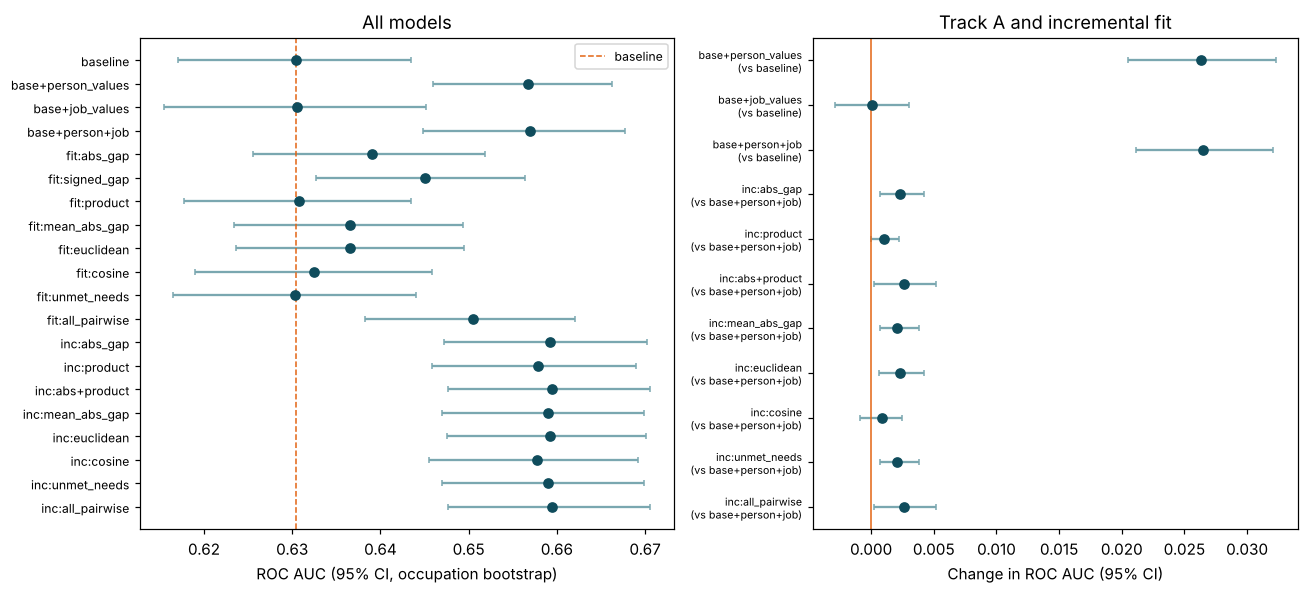

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
r = results.set_index("model").loc[names]
ax = axes[0]; yy_ = np.arange(len(r))[::-1]
ax.errorbar(r.roc_auc, yy_, xerr=[r.roc_auc - r.auc_ci_low, r.auc_ci_high - r.roc_auc], fmt="o", color="#0F4C5C", ecolor="#7AA7B0", capsize=2)
ax.axvline(r.roc_auc["baseline"], ls="--", color="#E36414", lw=1, label="baseline")
ax.set_yticks(yy_); ax.set_yticklabels(r.index, fontsize=8); ax.set_xlabel("ROC AUC (95% CI, occupation bootstrap)")
ax.set_title("All models"); ax.legend(fontsize=8)
d = pd.concat([track_a, incremental]); ax = axes[1]; yd = np.arange(len(d))[::-1]
ax.errorbar(d.delta_auc, yd, xerr=[d.delta_auc - d.ci_low, d.ci_high - d.delta_auc], fmt="o", color="#0F4C5C", ecolor="#7AA7B0", capsize=2)
ax.axvline(0, color="#E36414", lw=1)
ax.set_yticks(yd); ax.set_yticklabels([f"{m}\n(vs {ref})" for m, ref in zip(d.model, d.reference)], fontsize=7)
ax.set_xlabel("Change in ROC AUC (95% CI)"); ax.set_title("Track A and incremental fit")
plt.tight_layout(); plt.show()

## 9. Robustness
**(a) Different fold splits.** Repeat the grouped CV with five seeds and look at the spread of pooled AUC.

In [11]:
seeds = [42, 1, 2, 3, 4]
rep = {n: [] for n in names}
for s in seeds:
    f = folds if s == SEED else get_folds(df, y, groups, seed=s)
    for n, kw in MODELS.items():
        p = preds[n] if s == SEED else oof(kw, df, y, f)
        rep[n].append(roc_auc_score(y, p))
seed_tab = pd.DataFrame({"mean_auc": {n: np.mean(v) for n, v in rep.items()},
                         "sd_across_seeds": {n: np.std(v) for n, v in rep.items()},
                         "min": {n: min(v) for n, v in rep.items()}, "max": {n: max(v) for n, v in rep.items()}}).round(4)
seed_tab.to_csv("m3_seed_stability.csv")
seed_tab

,mean_auc,sd_across_seeds,min,max
baseline,0.6300,0.0007,0.6291,0.6308
base+person_values,0.6562,0.0008,0.6552,0.6570
base+job_values,0.6307,0.0005,0.6300,0.6315
base+person+job,0.6569,0.0005,0.6562,0.6577
fit:abs_gap,0.6386,0.0009,0.6374,0.6396
fit:signed_gap,0.6446,0.0008,0.6434,0.6453
fit:product,0.6303,0.0008,0.6292,0.6310
fit:mean_abs_gap,0.6358,0.0010,0.6346,0.6369
fit:euclidean,0.6360,0.0009,0.6348,0.6371
fit:cosine,0.6317,0.0011,0.6303,0.6329


**(b) Cleaner occupation mappings only.** Some respondents' occupations map to O*NET by proxy or broader group (`MAPPING_IS_PROXY`). Re-run the key comparisons on the rows with a non-proxy mapping.

In [12]:
mask = ~df.MAPPING_IS_PROXY.astype(bool).values
d2, y2, g2 = df[mask].reset_index(drop=True), y[mask], groups[mask]
f2 = get_folds(d2, y2, g2)
keys = ["baseline", "base+person_values", "base+person+job", "fit:all_pairwise", "inc:abs+product", "inc:all_pairwise"]
p2 = {k: oof(MODELS[k], d2, y2, f2) for k in keys}
B2 = pd.DataFrame(boot_auc(y2, [p2[k] for k in keys], g2, n_rep=1000), columns=keys)
auc2 = {k: roc_auc_score(y2, p2[k]) for k in keys}
sens = pd.DataFrame({"auc": auc2,
    "delta_vs_baseline": {k: auc2[k] - auc2["baseline"] for k in keys},
    "delta_vs_person+job": {k: auc2[k] - auc2["base+person+job"] for k in keys}}).round(4)
print(f"non-proxy rows: {mask.sum()} of {len(df)} | occupations: {len(np.unique(g2))}")
sens.loc["inc:all_pairwise", "ci_vs_person+job"] = str((B2["inc:all_pairwise"] - B2["base+person+job"]).quantile([0.025, 0.975]).round(4).tolist())
sens.loc["inc:abs+product", "ci_vs_person+job"] = str((B2["inc:abs+product"] - B2["base+person+job"]).quantile([0.025, 0.975]).round(4).tolist())
sens

non-proxy rows: 50767 of 74016 | occupations: 102


,auc,delta_vs_baseline,delta_vs_person+job,ci_vs_person+job
baseline,0.6303,0.0000,-0.0229,NaN
base+person_values,0.6539,0.0237,0.0008,NaN
base+person+job,0.6531,0.0229,0.0000,NaN
fit:all_pairwise,0.6476,0.0173,-0.0055,NaN
inc:abs+product,0.6544,0.0241,0.0012,"[-0.002, 0.0042]"
inc:all_pairwise,0.6543,0.0241,0.0012,"[-0.002, 0.0042]"


## 10. Error types and which features matter
Confusion matrices use a 0.5 threshold (rows = true class, columns = predicted). The coefficients come from a fit on all data for interpretation only; person importances are reversed so higher = more important, and each coefficient is an odds ratio per 1 SD.

In [13]:
for name in ["baseline", "inc:abs+product"]:
    cm = confusion_matrix(y, (preds[name] >= 0.5).astype(int))
    print(name); print(pd.DataFrame(cm, index=["true unsatisfied", "true satisfied"], columns=["pred unsatisfied", "pred satisfied"]), "\n")

m = make_pipe(person=True, job=True).fit(df, y)
fn = m.named_steps["pre"].get_feature_names_out()
coef = pd.DataFrame({"feature": fn, "odds_ratio_per_SD": np.exp(m.named_steps["clf"].coef_[0])})
coef = coef[coef.feature.str.startswith(("person__", "job__"))].round(3)
coef.to_csv("m3_person_job_odds_ratios.csv", index=False)
coef.sort_values("odds_ratio_per_SD").to_string(index=False)

baseline
                  pred unsatisfied  pred satisfied
true unsatisfied              4129            3232
true satisfied               25168           41487 

inc:abs+product
                  pred unsatisfied  pred satisfied
true unsatisfied              4303            3058
true satisfied               23950           42705 



                        feature  odds_ratio_per_SD
                person__IMP_ADV              0.810
                person__IMP_BEN              0.911
                person__IMP_SAL              0.942
       job__ONET_WV_achievement              0.945
     job__ONET_WV_relationships              0.955
job__ONET_WV_working_conditions              0.987
           job__ONET_WV_support              1.048
               person__IMP_CHAL              1.049
                person__IMP_LOC              1.058
                person__IMP_IND              1.066
                person__IMP_SOC              1.072
      job__ONET_WV_independence              1.077
       job__ONET_WV_recognition              1.119
                person__IMP_SEC              1.187
               person__IMP_RESP              1.188

## 11. Takeaways
**Headline:** person-job *fit* adds a statistically detectable but very small amount of predictive power beyond what the person's own values already provide.

| Step | ROC AUC | Change |
|---|---|---|
| Baseline (background only) | 0.630 (0.617-0.644) | |
| + person values | 0.657 | +0.026 (0.021 to 0.032) vs baseline |
| + job (O*NET) values | 0.631 | +0.000 (-0.003 to 0.003) vs baseline |
| + person + job | 0.657 | +0.027 (0.021 to 0.032) vs baseline |
| + person + job + fit (abs gap + product) | 0.660 | +0.003 (0.000 to 0.005) vs person + job |

- **Track A:** nearly all the gain comes from knowing the person's own values. Occupation-level O*NET values alone add nothing.
- **Track B, standalone:** fit scores added to the baseline look useful (signed gap +0.015, all pairwise +0.020), but a gap like `person - job` contains the person's values, so most of that credit belongs to them. Distance-style scores (abs gap, mean abs gap, Euclidean) add about +0.006 to +0.009. Product, cosine and unmet-needs add about nothing.
- **Track B, incremental (the real test of "match"):** on top of both main effects, abs gap, mean abs gap, Euclidean, unmet-needs and abs + product add about +0.002 to +0.003 AUC with CIs that exclude 0. Cosine is indistinguishable from 0. The effect holds across five fold seeds (SD < 0.001) but shrinks to +0.001 with a CI that includes 0 when restricted to non-proxy mappings.
- **Practical size:** at a 0.5 threshold, F1 for the unsatisfied class goes 0.225 (baseline) to 0.241 (person + job) to 0.242 (+ fit). Fit barely changes error rates.
- **Overall level:** AUC of about 0.66 means most of the variation in satisfaction is not captured by anything in this file.

**Limits**
- My mapping of `FAC*` items to O*NET dimensions is an assumption, `FACLOC` and O*NET `support` have no counterpart, and z-scoring both sides puts a respondent's rank among people next to an occupation's rank among occupations.
- O*NET values vary across only 123 occupations, and 31% of respondents have a proxy mapping.
- The model is linear. Tree models, KNN or the Keras network might find interactions that logistic regression can't.
- Stated importance and satisfaction come from the same respondents, and everything here is correlational. Survey weights are not used, so results describe this sample.
- These numbers aren't comparable to the October baseline (0.577): that file had 6,849 rows and 25 occupations, this one has 74,016 rows and 123.

**Next steps:** run tree models, KNN and Keras on the same folds (`m3_folds.csv`), try alternative mappings and fit definitions, and break results out by group.
